# Inquilinos que gastan más del 40 % de su renta en vivienda

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "sobrecarga-coste-inquilinos"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Inquilinos que gastan más del 40 % de su renta en vivienda"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población en alquiler a precio de mercado"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
MUESTRA_MINIMA = 50  # vista por comunidades: hogares de inquilinos a precio de mercado en la muestra para dar el dato
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de la población que vive de alquiler a precio de mercado está en hogares cuyos gastos de vivienda superan el 40 % de su renta disponible (la «tasa de sobrecarga» de Eurostat).

**Cómo se lee.** Un valor de 30 significa que tres de cada diez inquilinos a precio de mercado dedican a la vivienda más del 40 % de su renta.

**Limitaciones.**
- Eurostat cuenta todos los gastos de la vivienda (alquiler, suministros, comunidad) y descuenta las ayudas a la vivienda.
- EE. UU. y Canadá: la OCDE solo cuenta hipoteca y alquiler, y en España da valores distintos de los de Eurostat; al no ser comparables, esas series quedan sin dato (ver la comparación en la transformación). La OCDE no publica una media de sus países.

**Vista por comunidades.** Eurostat no publica esta tasa por comunidad autónoma. El selector «Por comunidad» de la web la calcula con los microdatos de la Encuesta de Condiciones de Vida (ECV) del INE, la misma encuesta de la que sale el dato de Eurostat para España, y con la fórmula que publica Eurostat. El total de España de ese cálculo se compara con el de Eurostat para comprobarlo.

Es una encuesta: en las comunidades con pocos inquilinos en la muestra el resultado es poco fiable. Si una comunidad tiene menos de 50 hogares de inquilinos a precio de mercado en la encuesta de un año, su dato de ese año no se muestra (Eurostat marca como poco fiables las estimaciones con menos de 50 observaciones). Los microdatos empiezan en 2008, el primer año con la metodología de renta actual (base 2013).

## 2. Descarga

- **España y UE-27:** Eurostat `ilc_lvho07c` (inquilinos a precio de mercado, `RENT_MKT`, %).
- **Comparación:** OECD Affordable Housing Database, HC1.2 (hoja `HC12_A3_a`, «Rent (private)», proporción × 100).
- **Vista por comunidades:** INE, Encuesta de Condiciones de Vida, ficheros de microdatos transversales (base 2013), un zip por año desde 2008, con los ficheros de Eurostat de hogares (región, tenencia, costes de la vivienda, renta) y de personas (peso). No se guardan en el repositorio: se descargan al ejecutar el notebook (unos 500 MB en total).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, construir_vista_ccaa, write_grafica_data

from datetime import date

from lib import ecv, eurostat, oecd, oecd_ahd
from lib.tipos import FuenteMeta


def descargar():
    euro, f_euro = eurostat.get("ilc_lvho07c", {"freq": "A", "unit": "PC", "tenure": "RENT_MKT"}, desde=DESDE)
    ahd, _ = oecd_ahd.get("HC1-2-Housing-costs-over-income", "HC12_A3_a", categoria="Rent (private)",
                          paises={"Spain": "espana", "United States": "eeuu", "Canada": "canada"}, escala=100, desde=DESDE)
    return euro, f_euro, ahd


def descargar_ccaa():
    """Sobrecarga de los inquilinos a precio de mercado por comunidad, un año tras otro, calculada con los
    microdatos de la ECV (`lib/ecv.py`). Se para en el primer año que el INE aún no ha publicado."""
    filas, fuente = [], None
    for anio in range(ecv.PRIMER_ANIO, date.today().year + 1):
        try:
            ficheros, fuente_anio = ecv.get(anio)
        except ecv.EcvError:
            if anio < date.today().year - 1:
                raise  # un año que ya debería estar publicado
            break
        fuente = fuente or fuente_anio
        tasas = ecv.sobrecarga(ficheros, "alquiler_mercado")
        filas.append(tasas.reset_index().assign(periodo=anio))
    return pd.concat(filas, ignore_index=True), fuente


euro, f_euro, ahd = descargar()
ccaa, fuente_ecv = descargar_ccaa()

## 3. Transformación

Se compara en España la cifra de Eurostat con la de la OCDE. Si no coinciden, EE. UU. y Canadá se dejan sin dato en lugar de mezclar dos definiciones.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]

# ¿Es comparable la OCDE con Eurostat? Se mira en España, que está en las dos fuentes
comun = euro[euro.serie == "espana"].merge(ahd[ahd.serie == "espana"], on="periodo", suffixes=("_eurostat", "_ocde"))
DIF = (comun["valor_ocde"] - comun["valor_eurostat"]).abs().mean()
print(comun.round(1).to_string(index=False))
print(f"Diferencia media en España (sobrecarga): {DIF:.1f} puntos")

df, fuentes = euro, f_euro
AHD = ("OECD", "Affordable Housing Database, HC1-2-Housing-costs-over-income (HC12_A3_a, consultada, no usada)", "https://webfs.oecd.org/els-com/Affordable_Housing_Database/HC1-2-Housing-costs-over-income.xlsx")
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": AHD, "eeuu": AHD, "canada": AHD})

NOTAS = [
    "España y UE-27: Eurostat ilc_lvho07c, tasa de sobrecarga del coste de la vivienda de la población en alquiler a precio de mercado: gastos totales de la vivienda, descontadas las ayudas, por encima del 40 % de la renta disponible del hogar. UE-27 de composición actual (EU27_2020).",
    f"EE. UU. y Canadá: la OECD Affordable Housing Database (HC1.2) solo cuenta hipoteca y alquiler; en España difiere de la cifra de Eurostat en {DIF:.1f} puntos de media en los años comunes, así que no es comparable y esas series quedan sin dato.",
    "OCDE: la OECD Affordable Housing Database no publica una media de sus países en las series anuales.",
]

# Vista por comunidades. Comprobación: el total de España del cálculo frente al dato de Eurostat
espana_calculo = ccaa[ccaa.serie == "espana"].set_index("periodo")["tasa"]
contraste = pd.DataFrame({"cálculo ECV": espana_calculo, "Eurostat": euro[euro.serie == "espana"].set_index("periodo")["valor"]}).dropna()
contraste["diferencia"] = contraste["cálculo ECV"] - contraste["Eurostat"]
display(contraste.round(2))
DIF_MAX = contraste["diferencia"].abs().max()
assert DIF_MAX < 1.5, f"el cálculo con los microdatos se aleja de Eurostat ({DIF_MAX:.1f} puntos): ¿ha cambiado algún fichero?"

# Sin dato si la muestra es pequeña (España siempre tiene muestra suficiente)
pocos = ccaa[(ccaa.serie != "espana") & (ccaa.hogares < MUESTRA_MINIMA)]
df_ccaa = ccaa.assign(valor=ccaa["tasa"].where((ccaa.serie == "espana") | (ccaa.hogares >= MUESTRA_MINIMA)))
con_dato = set(df_ccaa.loc[df_ccaa.valor.notna(), "serie"])
df_ccaa = df_ccaa[df_ccaa.serie.isin(con_dato)][["serie", "periodo", "valor"]]
display(ccaa.pivot(index="periodo", columns="serie", values="hogares"))


def tramos(años: list[int]) -> str:
    """«2009-2013, 2015 y 2018»: años seguidos agrupados en intervalos."""
    grupos: list[list[int]] = []
    for a in sorted(años):
        if grupos and a == grupos[-1][-1] + 1:
            grupos[-1].append(a)
        else:
            grupos.append([a])
    partes = [f"{g[0]}-{g[-1]}" if len(g) > 1 else str(g[0]) for g in grupos]
    return partes[0] if len(partes) == 1 else f"{', '.join(partes[:-1])} y {partes[-1]}"


from lib.ccaa import NOMBRES_CCAA

ANIOS = sorted(ccaa.periodo.unique())
fuera = [
    f"{NOMBRES_CCAA[s]} ({'todos los años' if len(g) == len(ANIOS) else tramos(g.periodo.tolist())})"
    for s, g in sorted(pocos.groupby("serie"), key=lambda x: NOMBRES_CCAA[x[0]])
]
fuentes_ccaa = [
    FuenteMeta(s, ecv.ORGANISMO,
               f"Encuesta de Condiciones de Vida, microdatos {ANIOS[0]}-{ANIOS[-1]} (base 2013): cálculo propio con la fórmula de Eurostat",
               ecv.URL_MICRODATOS, fuente_ecv.fecha_consulta)
    for s in sorted(con_dato)
]
NOTAS_CCAA = [
    "Cálculo propio con los microdatos de la Encuesta de Condiciones de Vida del INE y la fórmula de Eurostat (EU-SILC methodology, housing conditions): personas que residen en hogares en alquiler a precio de mercado cuyos gastos de vivienda, descontadas las ayudas a la vivienda, superan el 40 % de su renta disponible, también sin las ayudas; ponderadas con el peso transversal de la encuesta. Eurostat no publica esta tasa por comunidad autónoma.",
    f"España es el total del mismo cálculo; difiere del dato publicado por Eurostat de la vista España en {f"{DIF_MAX:.1f}".replace(".", ",")} puntos como máximo entre {contraste.index.min()} y {contraste.index.max()}.",
    f"Es una encuesta: el dato de una comunidad no se muestra los años en que tiene menos de {MUESTRA_MINIMA} hogares de inquilinos a precio de mercado en la muestra"
    + (f": {'; '.join(fuera)}." if fuera else "."),
    f"Los microdatos empiezan en {ANIOS[0]}, el primer año con la metodología de renta actual de la encuesta (base 2013); los anteriores no son comparables.",
]
vista_ccaa = construir_vista_ccaa(df_ccaa, fuentes_ccaa, unidad=UNIDAD, notas=NOTAS_CCAA, desde=DESDE)
for n in NOTAS_CCAA:
    print("-", n)

serie_eurostat  periodo  valor_eurostat serie_ocde  valor_ocde
        espana     2010            43.4     espana        24.8
        espana     2011            42.7     espana        25.3
        espana     2012            44.7     espana        25.0
        espana     2013            42.3     espana        22.8
        espana     2014            47.5     espana        27.2
        espana     2015            43.3     espana        23.5
        espana     2016            43.0     espana        22.3
        espana     2017            42.1     espana        25.6
        espana     2018            38.1     espana        20.3
        espana     2019            37.4     espana        23.6
        espana     2020            35.9     espana        23.0
        espana     2021            40.9     espana        28.3
        espana     2022            39.4     espana        24.8
        espana     2023            30.6     espana        20.0
        espana     2024            28.1     espana     

,cálculo ECV,Eurostat,diferencia
periodo,,,
2008,44.15,43.4,0.75
2009,40.91,41.4,-0.49
2010,44.36,43.4,0.96
2011,43.33,42.7,0.63
2012,44.82,44.7,0.12
2013,42.49,42.3,0.19
2014,47.94,47.5,0.44
2015,43.21,43.3,-0.09
2016,43.16,43.0,0.16


serie,ES-AN,ES-AR,ES-AS,ES-CB,ES-CE,ES-CL,ES-CM,ES-CN,ES-CT,ES-EX,ES-GA,ES-IB,ES-MC,ES-MD,ES-ML,ES-NC,ES-PV,ES-RI,ES-VC,espana
periodo,,,,,,,,,,,,,,,,,,,,
2008,76,42,57,18,14,51,44,60,137,22,50,77,42,110,11,33,38,42,64,988
2009,76,43,50,26,6,56,46,61,167,20,62,68,42,132,15,29,36,39,62,1036
2010,85,52,53,25,10,61,57,62,176,21,64,79,34,137,18,36,40,30,62,1102
2011,84,61,37,25,8,61,62,55,205,20,60,60,29,124,21,29,49,48,61,1099
2012,79,47,29,20,17,54,53,50,187,37,61,60,35,135,12,24,36,36,69,1041
2013,86,49,40,20,15,63,48,52,180,24,58,68,50,135,28,29,50,30,68,1093
2014,77,54,39,22,17,62,29,47,192,25,53,73,56,154,24,33,55,33,72,1117
2015,66,45,45,37,13,49,38,40,190,31,64,70,49,213,23,32,58,35,68,1166
2016,82,33,53,41,14,67,48,34,530,26,68,65,52,246,21,35,60,36,76,1587


- Cálculo propio con los microdatos de la Encuesta de Condiciones de Vida del INE y la fórmula de Eurostat (EU-SILC methodology, housing conditions): personas que residen en hogares en alquiler a precio de mercado cuyos gastos de vivienda, descontadas las ayudas a la vivienda, superan el 40 % de su renta disponible, también sin las ayudas; ponderadas con el peso transversal de la encuesta. Eurostat no publica esta tasa por comunidad autónoma.
- España es el total del mismo cálculo; difiere del dato publicado por Eurostat de la vista España en 1,0 puntos como máximo entre 2008 y 2025.
- Es una encuesta: el dato de una comunidad no se muestra los años en que tiene menos de 50 hogares de inquilinos a precio de mercado en la muestra: Aragón (2008-2009, 2012-2013 y 2015-2017); Asturias (2011-2015); Baleares (2017); Canarias (2014-2018); Cantabria (2008-2019); Castilla y León (2015); Castilla-La Mancha (2008-2009 y 2013-2016); Ceuta (todos los años); Extremadura (2008-2020); Galicia (2018); 

## 4. Visualización

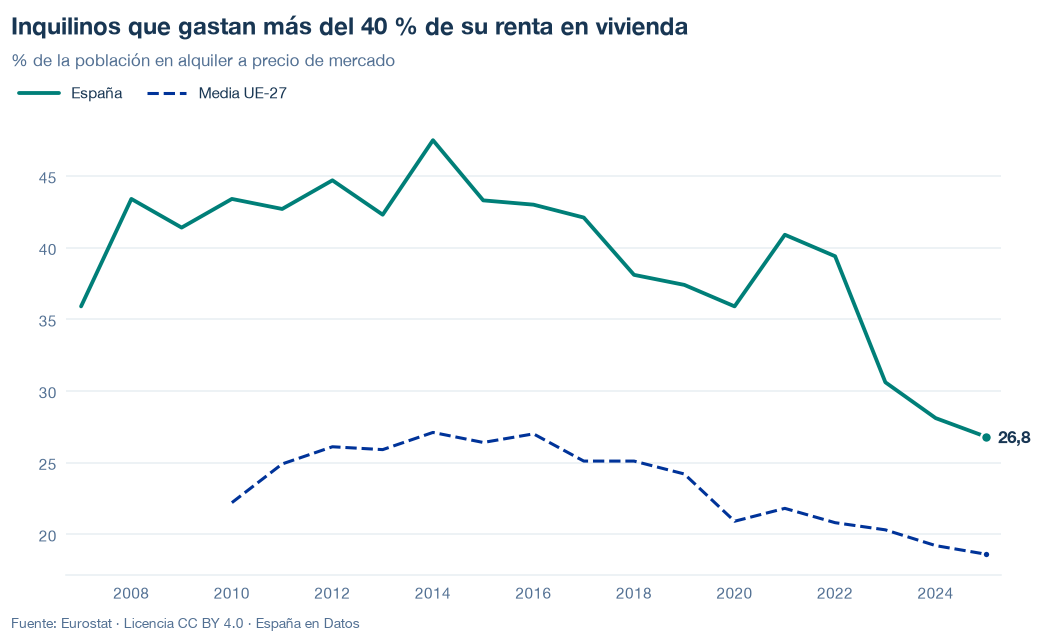

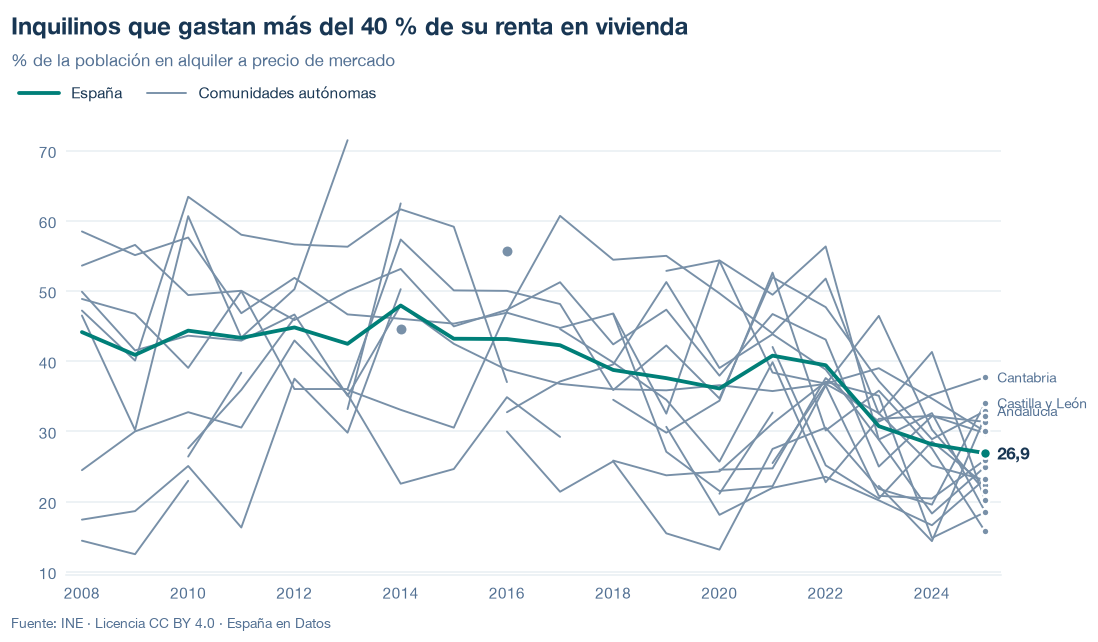

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, ccaa=vista_ccaa,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)
estilos.mostrar(estilos.figura_ccaa(datos, titulo=TITULO))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, ccaa=vista_ccaa,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/sobrecarga-coste-inquilinos.json y data/sobrecarga-coste-inquilinos.csv


## 6. Fuentes, notas y licencia

- Eurostat, `ilc_lvho07c`.
- OECD Affordable Housing Database, HC1.2 (`HC12_A3_a`), solo para la comparación.
- Vista por comunidades: INE, Encuesta de Condiciones de Vida, ficheros de microdatos transversales (base 2013), cálculo propio con la fórmula de Eurostat.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.